# ACE Classification & Pattern Identification

In [1]:
from pathlib import Path
from IPython.display import display, Image, Markdown
cwd = Path.cwd().resolve()
if (cwd.parent / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv').exists():
    ROOT = cwd
elif (cwd / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv').exists():
    ROOT = cwd / 'ACE_classification_gao'
else:
    raise FileNotFoundError('Start from the project root or ACE_classification_gao directory, and ensure the input CSV exists under Preprocessing.')
ROOT.mkdir(exist_ok=True)

# Keep English-language outputs separate from the Chinese results.
PROJECT_ROOT = ROOT
ROOT = PROJECT_ROOT / 'english'
ROOT.mkdir(exist_ok=True)

### ACE variable definitions, data validation, and descriptive analysis functions

In [2]:
"""Reproducible Section C analysis; all artifacts stay beside this script."""
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
SOURCE = PROJECT_ROOT.parent / 'Preprocessing' / 'BRFSS_2023_ACE_SCD_main.csv'
GROUPS = ['0', '1', '2-3', '4+']
LABELS = {'ACEDEPRS_bin': 'Household mental illness', 'ACEDRINK_bin': 'Household alcohol problems', 'ACEDRUGS_bin': 'Household drug misuse', 'ACEPRISN_bin': 'Household incarceration', 'ACEDIVRC_bin': 'Parental separation/divorce', 'ACEPUNCH_bin': 'Violence between parents', 'ACEHURT1_bin': 'Physical abuse', 'ACESWEAR_bin': 'Verbal abuse', 'ACETOUCH_bin': 'Sexual touching', 'ACETTHEM_bin': 'Made to touch sexually', 'ACEHVSEX_bin': 'Forced sex'}
COLS = list(LABELS)
DEMOGRAPHICS = {'sex': ['Male', 'Female', 'Missing'], 'education': ['High school or less', 'Attended college', 'College graduate', 'Missing'], 'income': ['<$15k', '$15-25k', '$25-35k', '$35-50k', '$50-100k', '$100-200k', '>=$200k', 'Missing'], 'age_group': ['45-54', '55-64', '65-74', '75+', 'Missing'], 'marital': ['Married or living with partner', 'Previously married', 'Never married', 'Missing'], 'race': ['White, non-Hispanic', 'Black, non-Hispanic', 'Hispanic', 'Others, non-Hispanic', 'Missing']}

def save_table(frame, name, index=False):
    frame.to_csv(ROOT / 'tables' / (name + '.csv'), index=index, encoding='utf-8-sig')

def save_figure(fig, name):
    fig.savefig(ROOT / 'figures' / (name + '.png'), dpi=300, bbox_inches='tight')
    fig.savefig(ROOT / 'figures' / (name + '.pdf'), bbox_inches='tight')
    plt.close(fig)

def load_data():
    d = pd.read_csv(SOURCE)
    if not d[COLS].isin([0, 1]).all().all():
        raise ValueError('ACE items must be complete binary values; missing is never scored as zero.')
    if not (np.isfinite(d['_LLCPWT']) & d['_LLCPWT'].gt(0)).all():
        raise ValueError('Survey weights must be finite and positive.')
    d['ACE_score_recalculated'] = d[COLS].sum(axis=1, min_count=11).astype(int)
    if not d['ACE_score_recalculated'].eq(d['ACE_score_11']).all():
        raise ValueError('Recalculated scores differ from preprocessing.')
    if not d['_AGE80'].between(45, 80).all():
        raise ValueError('Unexpected age outside the analytic sample.')
    for i, col in enumerate(COLS):
        mapping = {1: 1, 2: 0} if i < 5 else {1: 0, 2: 1, 3: 1}
        if not d[col.removesuffix('_bin')].map(mapping).eq(d[col]).all():
            raise ValueError(f'Raw/binary mismatch: {col}')
    d['ace_group'] = pd.cut(d['ACE_score_recalculated'], [-1, 0, 1, 3, 11], labels=GROUPS)
    d['source_row'] = np.arange(2, len(d) + 2)
    d['sex'] = d['SEXVAR'].map({1: 'Male', 2: 'Female'}).fillna('Missing')
    d['education'] = d['EDUCA'].map({1: 'High school or less', 2: 'High school or less', 3: 'High school or less', 4: 'High school or less', 5: 'Attended college', 6: 'College graduate'}).fillna('Missing')
    d['income'] = d['INCOME3'].map({1: '<$15k', 2: '<$15k', 3: '$15-25k', 4: '$15-25k', 5: '$25-35k', 6: '$35-50k', 7: '$50-100k', 8: '$50-100k', 9: '$100-200k', 10: '$100-200k', 11: '>=$200k'}).fillna('Missing')
    d['age_group'] = pd.cut(d['_AGE80'], [44, 54, 64, 74, 80], labels=DEMOGRAPHICS['age_group'][:-1]).astype('object').fillna('Missing')
    d['marital'] = d['MARITAL'].map({1: 'Married or living with partner', 6: 'Married or living with partner', 2: 'Previously married', 3: 'Previously married', 4: 'Previously married', 5: 'Never married'}).fillna('Missing')
    d['race'] = d['_RACEGR3'].map({1: 'White, non-Hispanic', 2: 'Black, non-Hispanic', 3: 'Others, non-Hispanic', 4: 'Others, non-Hispanic', 5: 'Hispanic'}).fillna('Missing')
    return d

def distribution(d, column, order):
    g = d.groupby(column, observed=True).agg(n=(column, 'size'), weight_sum=('_LLCPWT', 'sum')).reindex(order, fill_value=0)
    g['unweighted_pct'] = 100 * g['n'] / len(d)
    g['weighted_pct'] = 100 * g['weight_sum'] / d['_LLCPWT'].sum()
    return g.rename_axis(column).reset_index()

def run_analysis():
    for folder in ['tables', 'figures', 'data']:
        (ROOT / folder).mkdir(exist_ok=True)
    plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
    d = load_data()
    d.to_csv(ROOT / 'data' / 'BRFSS_2023_ACE_classified.csv', index=False, encoding='utf-8-sig')
    groups = distribution(d, 'ace_group', GROUPS)
    scores = distribution(d, 'ACE_score_recalculated', range(12))
    save_table(groups, 'ace_group_distribution')
    save_table(scores, 'ace_score_distribution')
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    for ax, metric, title in zip(axes, ['n', 'weighted_pct'], ['Observed sample counts', 'Survey-weighted distribution']):
        bars = ax.bar(GROUPS, groups[metric], color=['#477D60', '#4E79A7', '#E6A23C', '#BD5252'])
        ax.bar_label(bars, labels=[f'{v:,.0f}' if metric == 'n' else f'{v:.1f}%' for v in groups[metric]], padding=4)
        ax.set(xlabel='ACE item score group', ylabel='Respondents' if metric == 'n' else 'Weighted %', title=title, ylim=(0, groups[metric].max() * 1.17))
    fig.tight_layout()
    save_figure(fig, 'Fig1_ACE_group_distribution')
    x = d[COLS].to_numpy(dtype=float)
    w = d['_LLCPWT'].to_numpy(dtype=float)
    counts = x.T @ x
    joint = 100 * (x.T @ (x * w[:, None])) / w.sum()
    means = np.average(x, axis=0, weights=w)
    cov = x.T @ (x * w[:, None]) / w.sum() - np.outer(means, means)
    phi = cov / np.sqrt(np.outer(means * (1 - means), means * (1 - means)))
    for matrix, name in [(counts, 'cooccurrence_unweighted_n'), (joint, 'cooccurrence_weighted_pct'), (phi, 'weighted_phi_correlation')]:
        save_table(pd.DataFrame(matrix, index=COLS, columns=COLS), name, index=True)
    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(joint, cmap='YlOrRd', vmin=0)
    ax.set_xticks(range(11), LABELS.values(), rotation=55, ha='right')
    ax.set_yticks(range(11), LABELS.values())
    for i in range(11):
        for j in range(11):
            ax.text(j, i, f'{joint[i, j]:.1f}', ha='center', va='center', color='white' if joint[i, j] > joint.max() * 0.6 else 'black', fontsize=8)
    fig.colorbar(im, ax=ax, label='Both items present: weighted % of all respondents')
    ax.set_title('ACE pairwise co-occurrence\nDiagonal = individual item prevalence; pairs may include other ACEs')
    save_figure(fig, 'Fig2_ACE_cooccurrence_heatmap')
    pairs = pd.DataFrame([{'item_1': COLS[i], 'item_2': COLS[j], 'n_both': int(counts[i, j]), 'weighted_joint_pct': joint[i, j], 'weighted_phi': phi[i, j]} for i in range(11) for j in range(i + 1, 11)]).sort_values('weighted_joint_pct', ascending=False)
    save_table(pairs, 'ace_pair_rankings')
    patterns = d.groupby(COLS, observed=True).agg(n=('SCD', 'size'), weight_sum=('_LLCPWT', 'sum')).reset_index().sort_values(['n'] + COLS, ascending=[False] + [True] * 11).reset_index(drop=True)
    patterns['pattern'] = patterns[COLS].astype(int).astype(str).agg(''.join, axis=1)
    patterns['n_ace_items'] = patterns[COLS].sum(axis=1).astype(int)
    patterns['unweighted_pct'] = 100 * patterns['n'] / len(d)
    patterns['weighted_pct'] = 100 * patterns['weight_sum'] / w.sum()
    patterns['description'] = patterns[COLS].apply(lambda r: ' + '.join((LABELS[c] for c in COLS if r[c])) or 'No ACEs', axis=1)
    save_table(patterns, 'ace_exact_patterns_all')
    top = patterns.loc[patterns['n_ace_items'] > 0].head(20).reset_index(drop=True)
    save_table(top, 'ace_exact_patterns_top20_exposed')
    fig = plt.figure(figsize=(17, 9))
    grid = fig.add_gridspec(2, 2, width_ratios=[4, 10], height_ratios=[4, 5], hspace=0.08, wspace=0.08)
    bars_ax = fig.add_subplot(grid[0, 1])
    matrix_ax = fig.add_subplot(grid[1, 1], sharex=bars_ax)
    sets_ax = fig.add_subplot(grid[1, 0], sharey=matrix_ax)
    bars = bars_ax.bar(range(len(top)), top['n'], color='#37788A')
    bars_ax.bar_label(bars, labels=[f'{n:,}' for n in top['n']], fontsize=8, rotation=45, padding=3)
    bars_ax.set(ylabel='Exact intersection size (unweighted n)', ylim=(0, top['n'].max() * 1.3))
    bars_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    for j, row in top.iterrows():
        active = np.flatnonzero(row[COLS].to_numpy(dtype=int))
        matrix_ax.scatter([j] * 11, range(11), color='#DDDDDD', s=25)
        matrix_ax.plot([j] * len(active), active, color='#244F60', linewidth=2)
        matrix_ax.scatter([j] * len(active), active, color='#244F60', s=40)
    matrix_ax.set(ylim=(10.6, -0.6), xlabel='Top 20 nonempty exact ACE combinations, ranked by sample count', xticks=[])
    matrix_ax.tick_params(axis='y', left=False, labelleft=False)
    sets_ax.barh(range(11), x.sum(axis=0), color='#BAA14D')
    sets_ax.set_yticks(range(11), LABELS.values(), fontsize=9)
    sets_ax.invert_xaxis()
    sets_ax.set_xlabel('All-sample item counts')
    zero = patterns.loc[patterns['n_ace_items'].eq(0)].iloc[0]
    coverage = top['n'].sum() / len(d) * 100
    fig.suptitle(f"ACE exact combinations (UpSet plot)\nNo ACEs: n={zero['n']:,}; displayed combinations cover {coverage:.1f}% of the full sample", y=0.98)
    save_figure(fig, 'Fig3_ACE_UpSet_top20')
    demographic_rows = []
    for variable, levels in DEMOGRAPHICS.items():
        for group in GROUPS:
            sub = d.loc[d['ace_group'].eq(group)]
            for level in levels:
                mask = sub[variable].eq(level)
                demographic_rows.append({'variable': variable, 'level': level, 'ace_group': group, 'n': int(mask.sum()), 'group_n': len(sub), 'unweighted_pct': 100 * mask.mean(), 'weighted_pct': 100 * sub.loc[mask, '_LLCPWT'].sum() / sub['_LLCPWT'].sum()})
    demographics = pd.DataFrame(demographic_rows)
    save_table(demographics, 'demographics_by_ace_group_long')
    wide = demographics.assign(cell=demographics.apply(lambda r: f"{r['n']:,} ({r['weighted_pct']:.1f}%)", axis=1)).pivot(index=['variable', 'level'], columns='ace_group', values='cell').reindex(columns=GROUPS)
    save_table(wide, 'demographics_by_ace_group_n_weighted_pct', index=True)
    for number, variables in [(4, ['sex', 'education', 'income']), (5, ['age_group', 'marital', 'race'])]:
        fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))
        for ax, variable in zip(axes, variables):
            block = demographics.loc[demographics['variable'].eq(variable)]
            bottom = np.zeros(4)
            levels = DEMOGRAPHICS[variable]
            colors = plt.get_cmap('tab20')(np.linspace(0, 0.9, len(levels)))
            for level, color in zip(levels, colors):
                values = block.loc[block['level'].eq(level)].set_index('ace_group').reindex(GROUPS)['weighted_pct'].to_numpy()
                ax.bar(GROUPS, values, bottom=bottom, label=level, color='#BBBBBB' if level == 'Missing' else color, width=0.7)
                for i, v in enumerate(values):
                    if v >= 7:
                        ax.text(i, bottom[i] + v / 2, f'{v:.1f}', ha='center', va='center', fontsize=8)
                bottom += values
            ax.set(title=variable.replace('_', ' ').title(), xlabel='ACE item score group', ylabel='Weighted within-group %', ylim=(0, 100))
            ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), frameon=False, fontsize=8)
        fig.suptitle('Demographic composition within ACE groups (missing retained)')
        fig.subplots_adjust(bottom=0.34, wspace=0.3, top=0.88)
        save_figure(fig, f'Fig{number}_demographics_' + '_'.join(variables))
    assert groups['n'].sum() == len(d) == patterns['n'].sum()
    assert np.isclose(groups['weighted_pct'].sum(), 100)
    assert np.allclose(demographics.groupby(['variable', 'ace_group'])['weighted_pct'].sum(), 100)
    assert np.allclose(joint, joint.T) and np.allclose(np.diag(joint), means * 100)
    assert np.allclose(np.diag(phi), 1)
    audit = {'source': str(SOURCE.relative_to(PROJECT_ROOT.parent)), 'source_sha256': hashlib.sha256(SOURCE.read_bytes()).hexdigest(), 'n': len(d), 'states': sorted(d['_STATE'].unique().astype(int).tolist()), 'ace_score_mismatches': int(d['ACE_score_recalculated'].ne(d['ACE_score_11']).sum()), 'raw_binary_mismatches': 0, 'ace_missing_cells': int(d[COLS].isna().sum().sum()), 'exact_patterns': len(patterns), 'top20_full_sample_coverage_pct': coverage, 'validation': 'passed', 'versions': {'pandas': pd.__version__, 'numpy': np.__version__}}
    (ROOT / 'tables' / 'validation.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
    return {'data': d, 'groups': groups, 'scores': scores, 'pairs': pairs, 'patterns': patterns, 'demographics': demographics, 'audit': audit}


## Run the analysis and generate results

In [3]:
result = run_analysis()
df = result['data']
print(f'Sample size: {len(df):,}; All primary analysis outputs have been generated.')

Sample size: 35,754; All primary analysis outputs have been generated.


## 1. Data quality and scoring

The complete implementation is provided in the function definitions above. All 11 items must be complete binary responses; missing values are never scored as zero. Recalculated scores are checked against the preprocessing score.

In [4]:
display(pd.DataFrame({'Variable': COLS, 'Plot label': list(LABELS.values())}))
# min_count prevents incomplete responses from being treated as complete scores.
recalculated = df[COLS].sum(axis=1, min_count=11)
assert recalculated.eq(df['ACE_score_11']).all()
ace_group = pd.cut(recalculated, bins=[-1, 0, 1, 3, 11], labels=['0', '1', '2-3', '4+'])
assert ace_group.eq(df['ace_group']).all()
display(df[['source_row', *COLS, 'ACE_score_11', 'ACE_score_recalculated', 'ace_group']].head())
display(result['audit'])

,Variable,Plot label
0,ACEDEPRS_bin,Household mental illness
1,ACEDRINK_bin,Household alcohol problems
2,ACEDRUGS_bin,Household drug misuse
3,ACEPRISN_bin,Household incarceration
4,ACEDIVRC_bin,Parental separation/divorce
5,ACEPUNCH_bin,Violence between parents
6,ACEHURT1_bin,Physical abuse
7,ACESWEAR_bin,Verbal abuse
8,ACETOUCH_bin,Sexual touching
9,ACETTHEM_bin,Made to touch sexually


,source_row,ACEDEPRS_bin,ACEDRINK_bin,ACEDRUGS_bin,ACEPRISN_bin,ACEDIVRC_bin,ACEPUNCH_bin,ACEHURT1_bin,ACESWEAR_bin,ACETOUCH_bin,ACETTHEM_bin,ACEHVSEX_bin,ACE_score_11,ACE_score_recalculated,ace_group
0,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
1,3,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2,2,2-3
2,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1,1,1
3,5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1,1,1
4,6,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0


{'source': 'Preprocessing\\BRFSS_2023_ACE_SCD_main.csv',
 'source_sha256': 'aa55c4e6d017891c9e77454af91d4c8493c5a3b2484c6d3abf370e77571c3c9f',
 'n': 35754,
 'states': [10, 12, 13, 29, 32, 34, 41, 44, 47, 51],
 'ace_score_mismatches': 0,
 'raw_binary_mismatches': 0,
 'ace_missing_cells': 0,
 'exact_patterns': 1020,
 'top20_full_sample_coverage_pct': 32.723611344185265,
 'validation': 'passed',
 'versions': {'pandas': '2.3.2', 'numpy': '1.26.4'}}

## 2. Distribution of ACE score groups

,ace_group,n,weight_sum,unweighted_pct,weighted_pct
0,0,14342,8704908.403,40.113,38.775
1,1,8245,5185211.742,23.060,23.097
2,2-3,7649,4917069.206,21.393,21.902
3,4+,5518,3642836.483,15.433,16.226


,ACE_score_recalculated,n,weight_sum,unweighted_pct,weighted_pct
0,0,14342,8704908.403,40.113,38.775
1,1,8245,5185211.742,23.060,23.097
2,2,4626,3085125.213,12.938,13.742
3,3,3023,1831943.993,8.455,8.160
4,4,2005,1301519.631,5.608,5.797
5,5,1317,820428.002,3.684,3.654
6,6,890,608913.541,2.489,2.712
7,7,578,391134.064,1.617,1.742
8,8,359,230597.148,1.004,1.027
9,9,194,152690.462,0.543,0.680


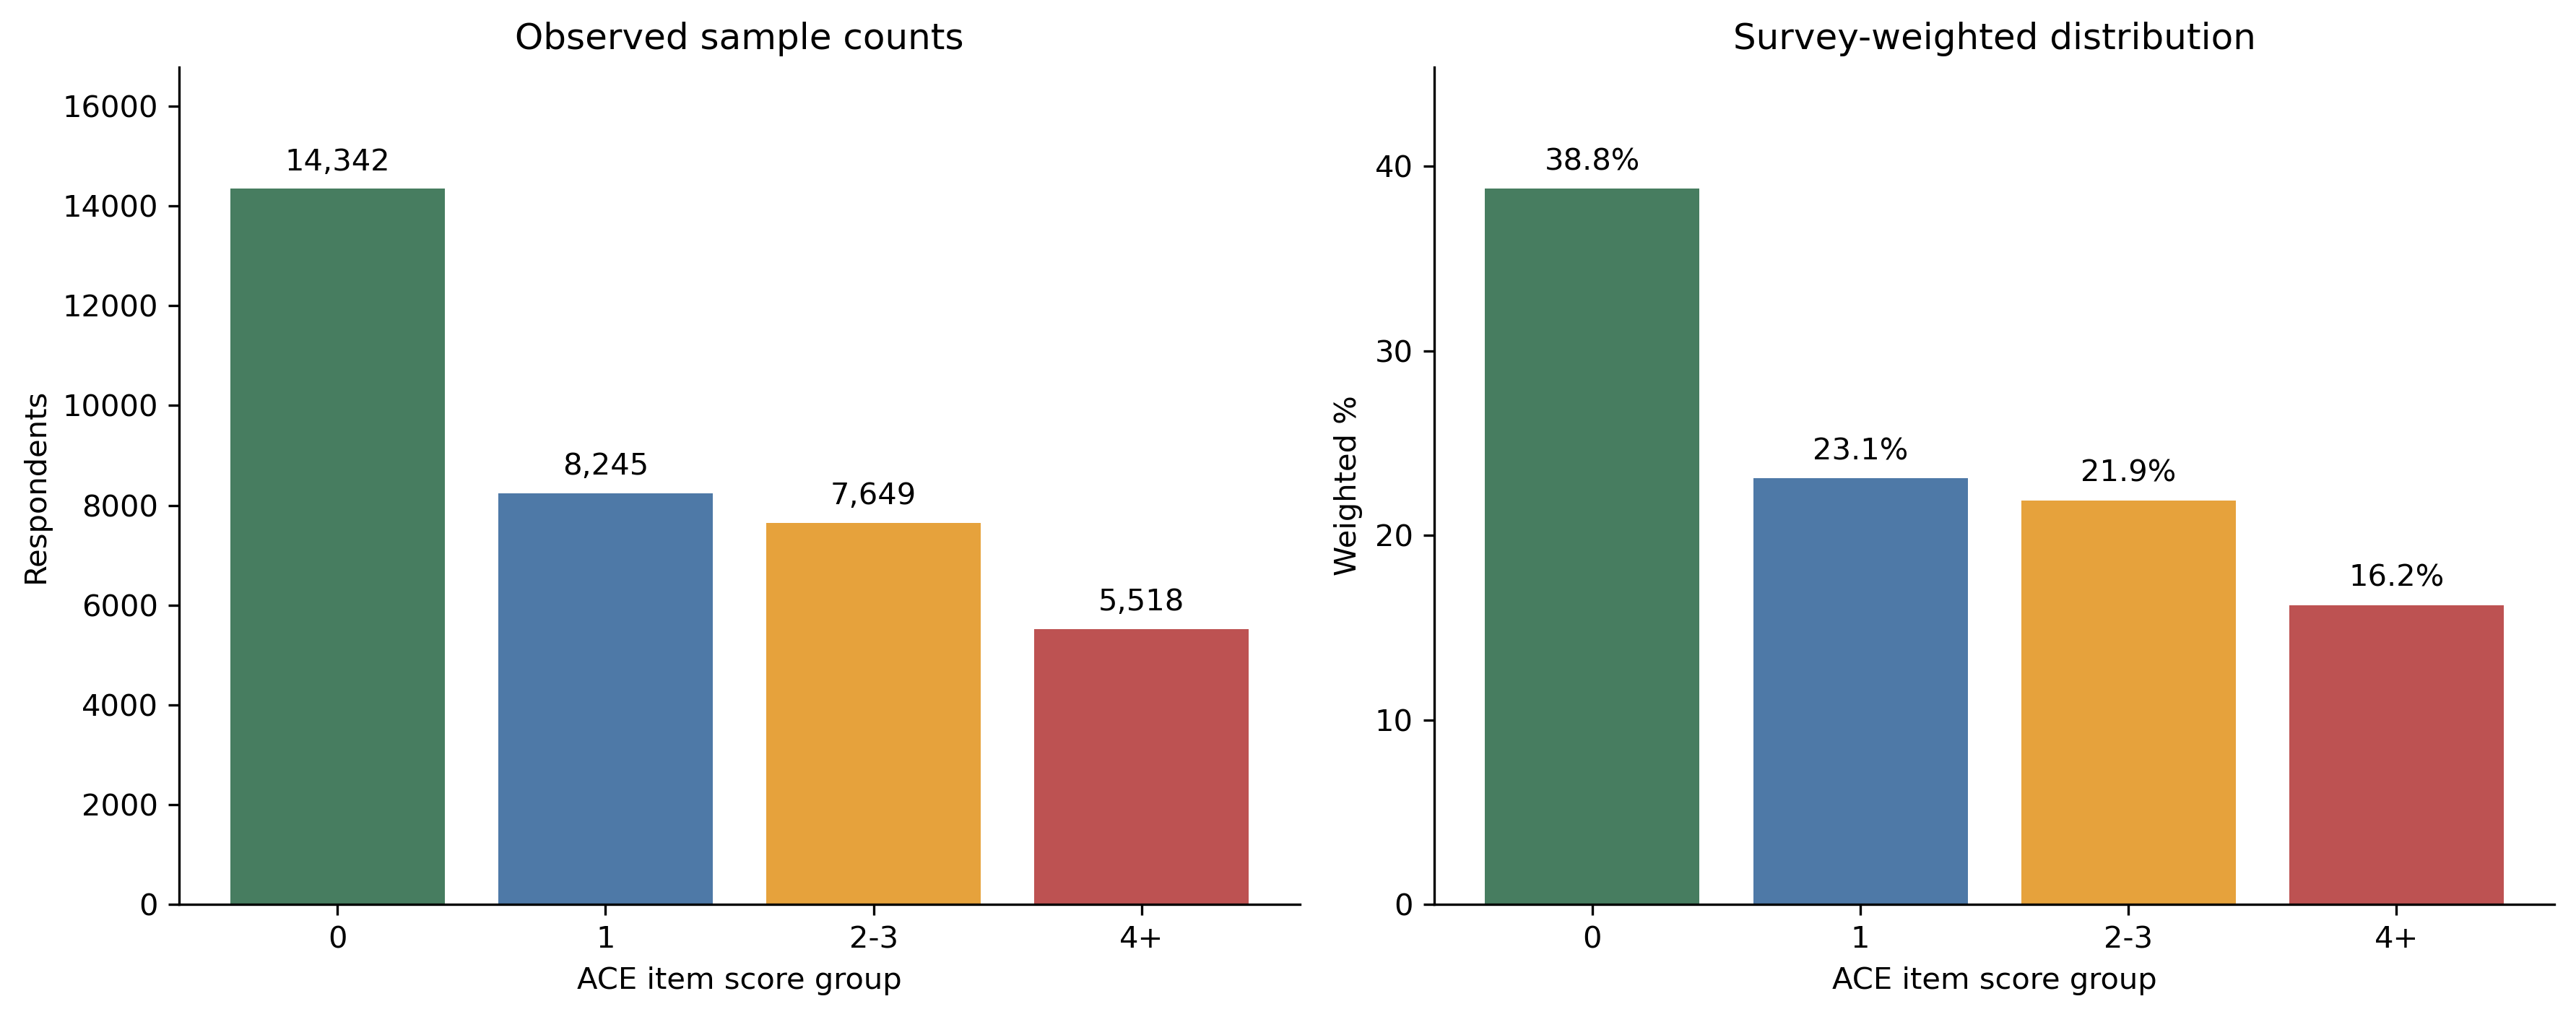

In [5]:
display(result['groups'].round(3))
display(result['scores'].round(3))
display(Image(filename=str(ROOT / 'figures/Fig1_ACE_group_distribution.png')))

## 3. ACE co-occurrence heatmap

Each cell is the survey-weighted percentage with both ACE items present, using the entire analytic sample as the denominator. Other ACEs may also be present. The diagonal shows individual-item prevalence. Joint prevalence differs from association strength, so a weighted phi correlation matrix is also exported. Pair rankings exclude the diagonal.

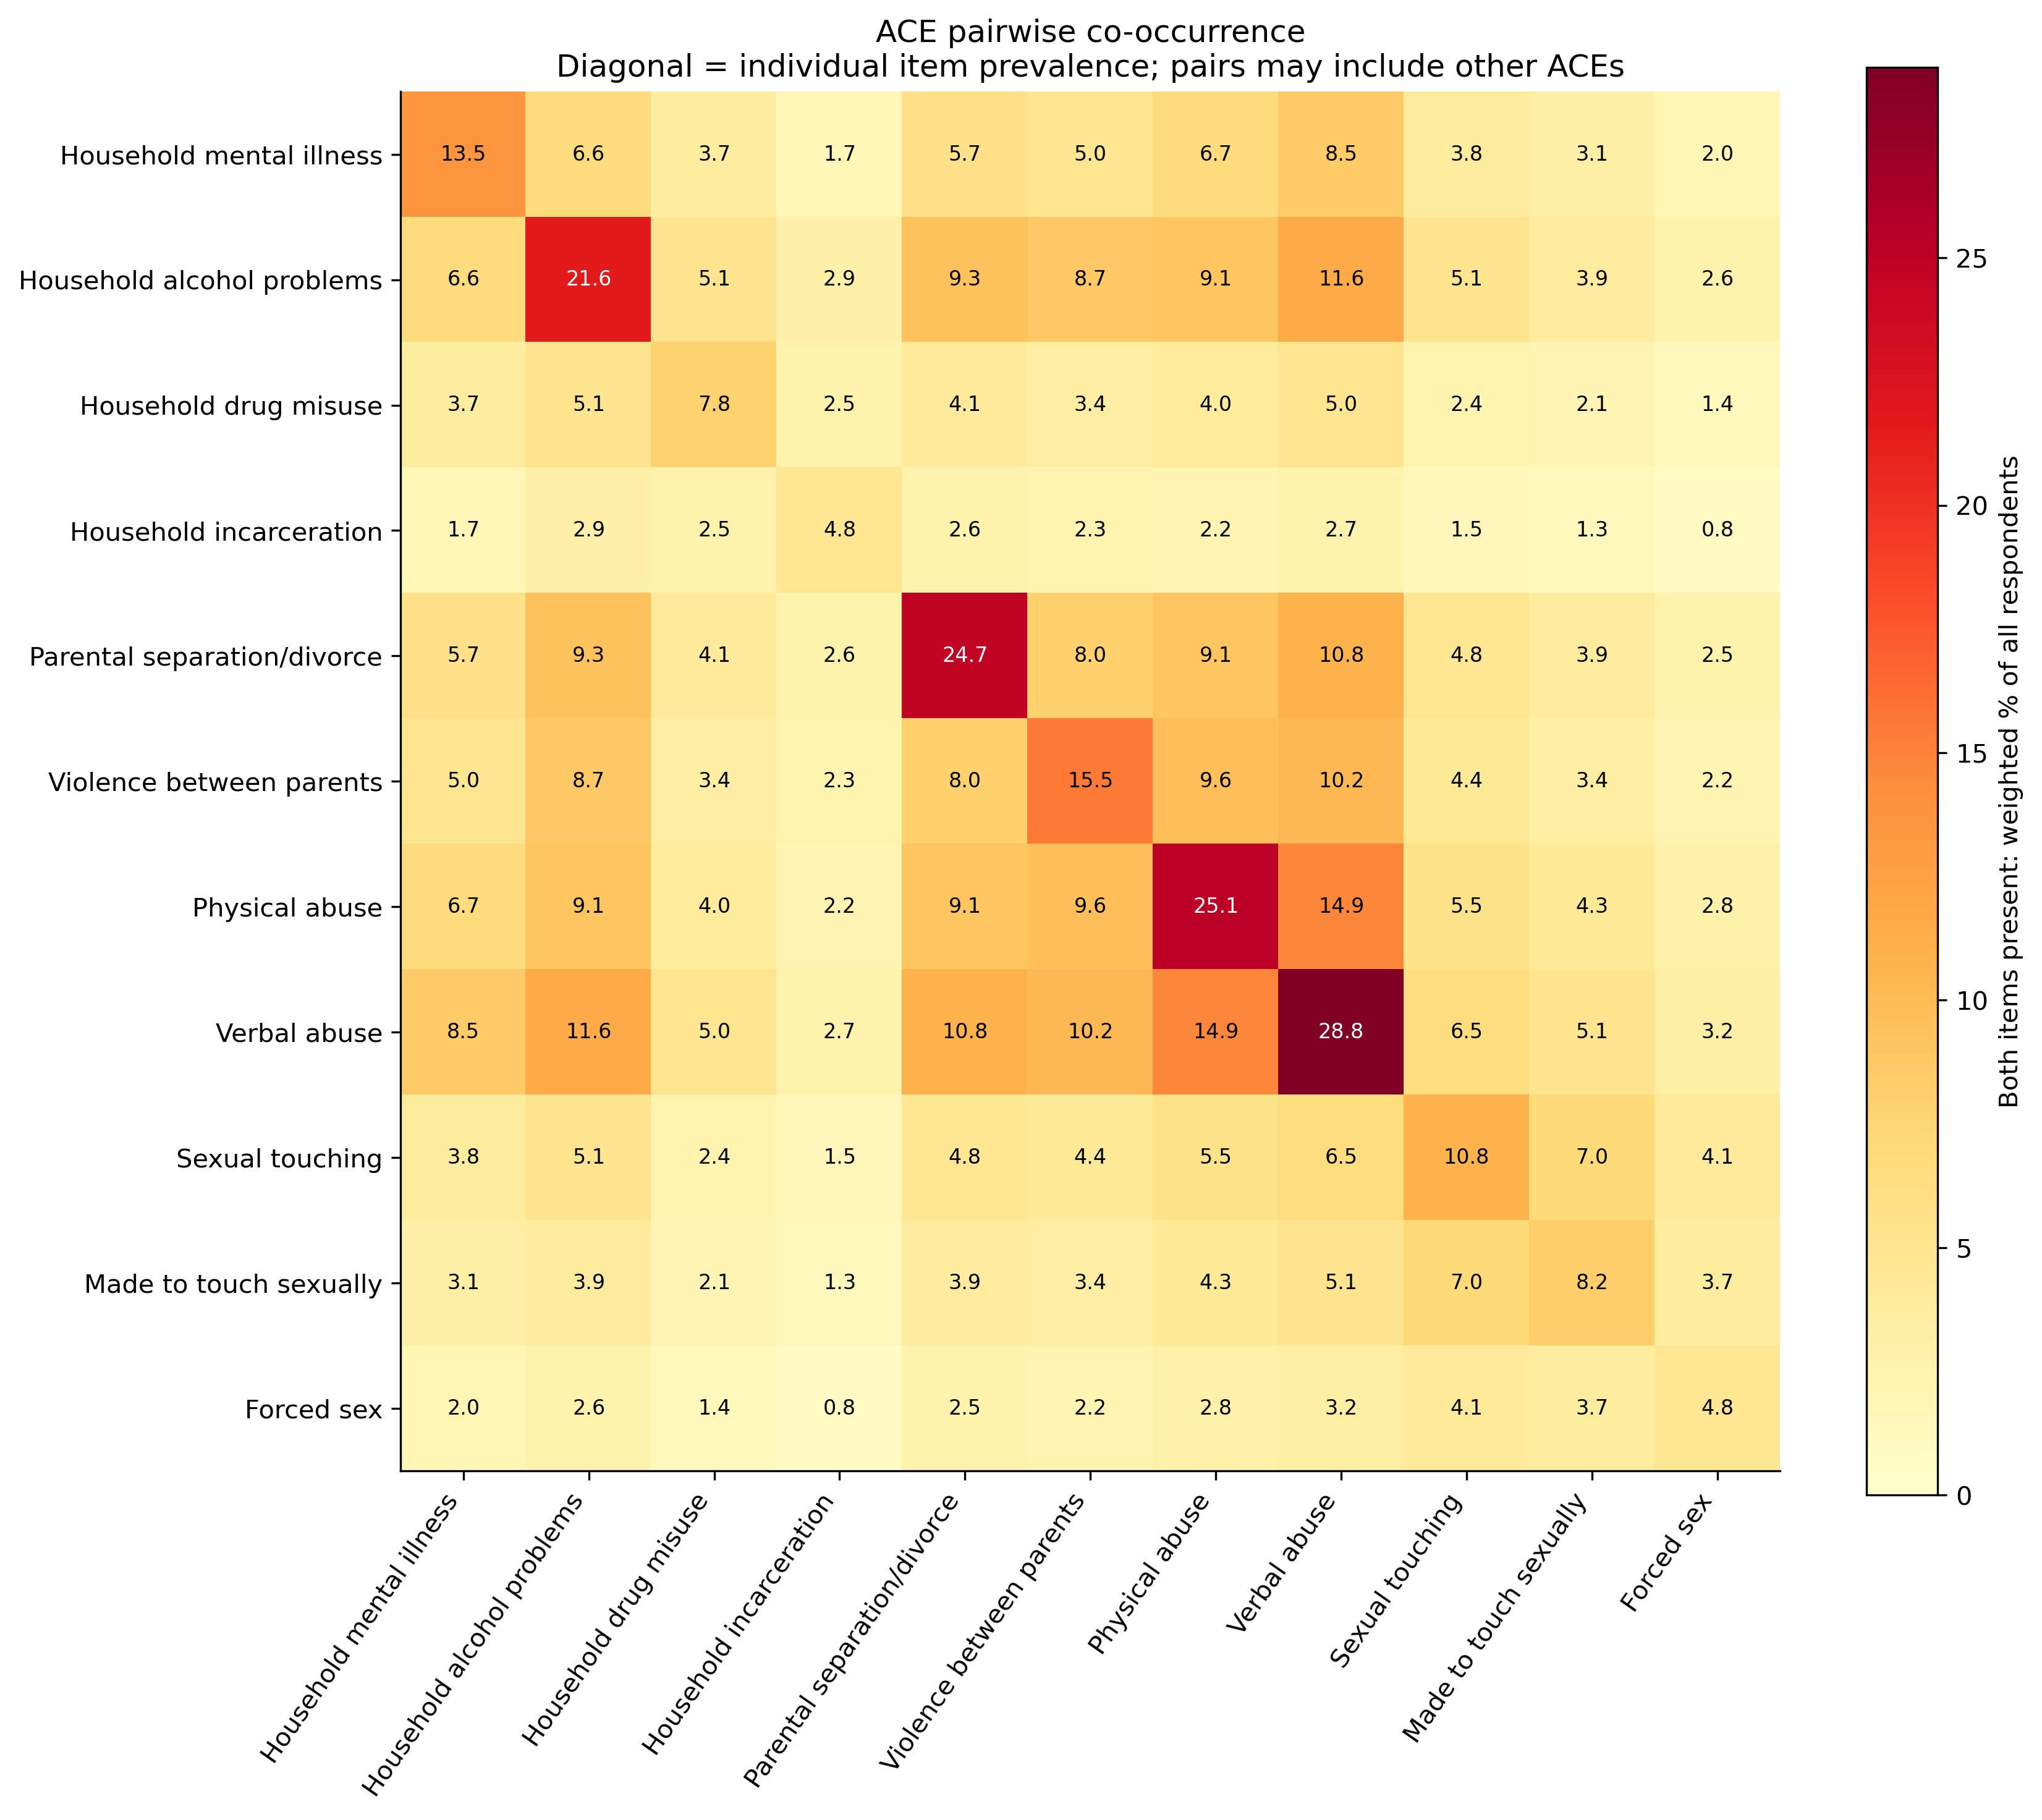

,item_1,item_2,n_both,weighted_joint_pct,weighted_phi
45,ACEHURT1_bin,ACESWEAR_bin,5171,14.858,0.387
15,ACEDRINK_bin,ACESWEAR_bin,4185,11.575,0.287
36,ACEDIVRC_bin,ACESWEAR_bin,3485,10.752,0.185
41,ACEPUNCH_bin,ACESWEAR_bin,3409,10.230,0.352
40,ACEPUNCH_bin,ACEHURT1_bin,3091,9.609,0.365
12,ACEDRINK_bin,ACEDIVRC_bin,3056,9.325,0.224
35,ACEDIVRC_bin,ACEHURT1_bin,2841,9.116,0.155
14,ACEDRINK_bin,ACEHURT1_bin,3250,9.099,0.206
13,ACEDRINK_bin,ACEPUNCH_bin,2919,8.726,0.362
6,ACEDEPRS_bin,ACESWEAR_bin,3191,8.542,0.299


In [6]:
display(Image(filename=str(ROOT / 'figures/Fig2_ACE_cooccurrence_heatmap.png')))
display(result['pairs'].head(10).round(3))

## 4. Exact ACE combinations and UpSet plot

Each column represents a mutually exclusive complete response pattern: dark dots indicate presence and gray dots indicate absence. Top bars show unweighted counts; the left panel shows item counts across the entire sample. The 20 most frequent nonempty patterns are displayed, with the no-ACE pattern reported separately in the title. The layout uses Matplotlib and does not require upsetplot. All patterns and their weighted percentages are exported to CSV.

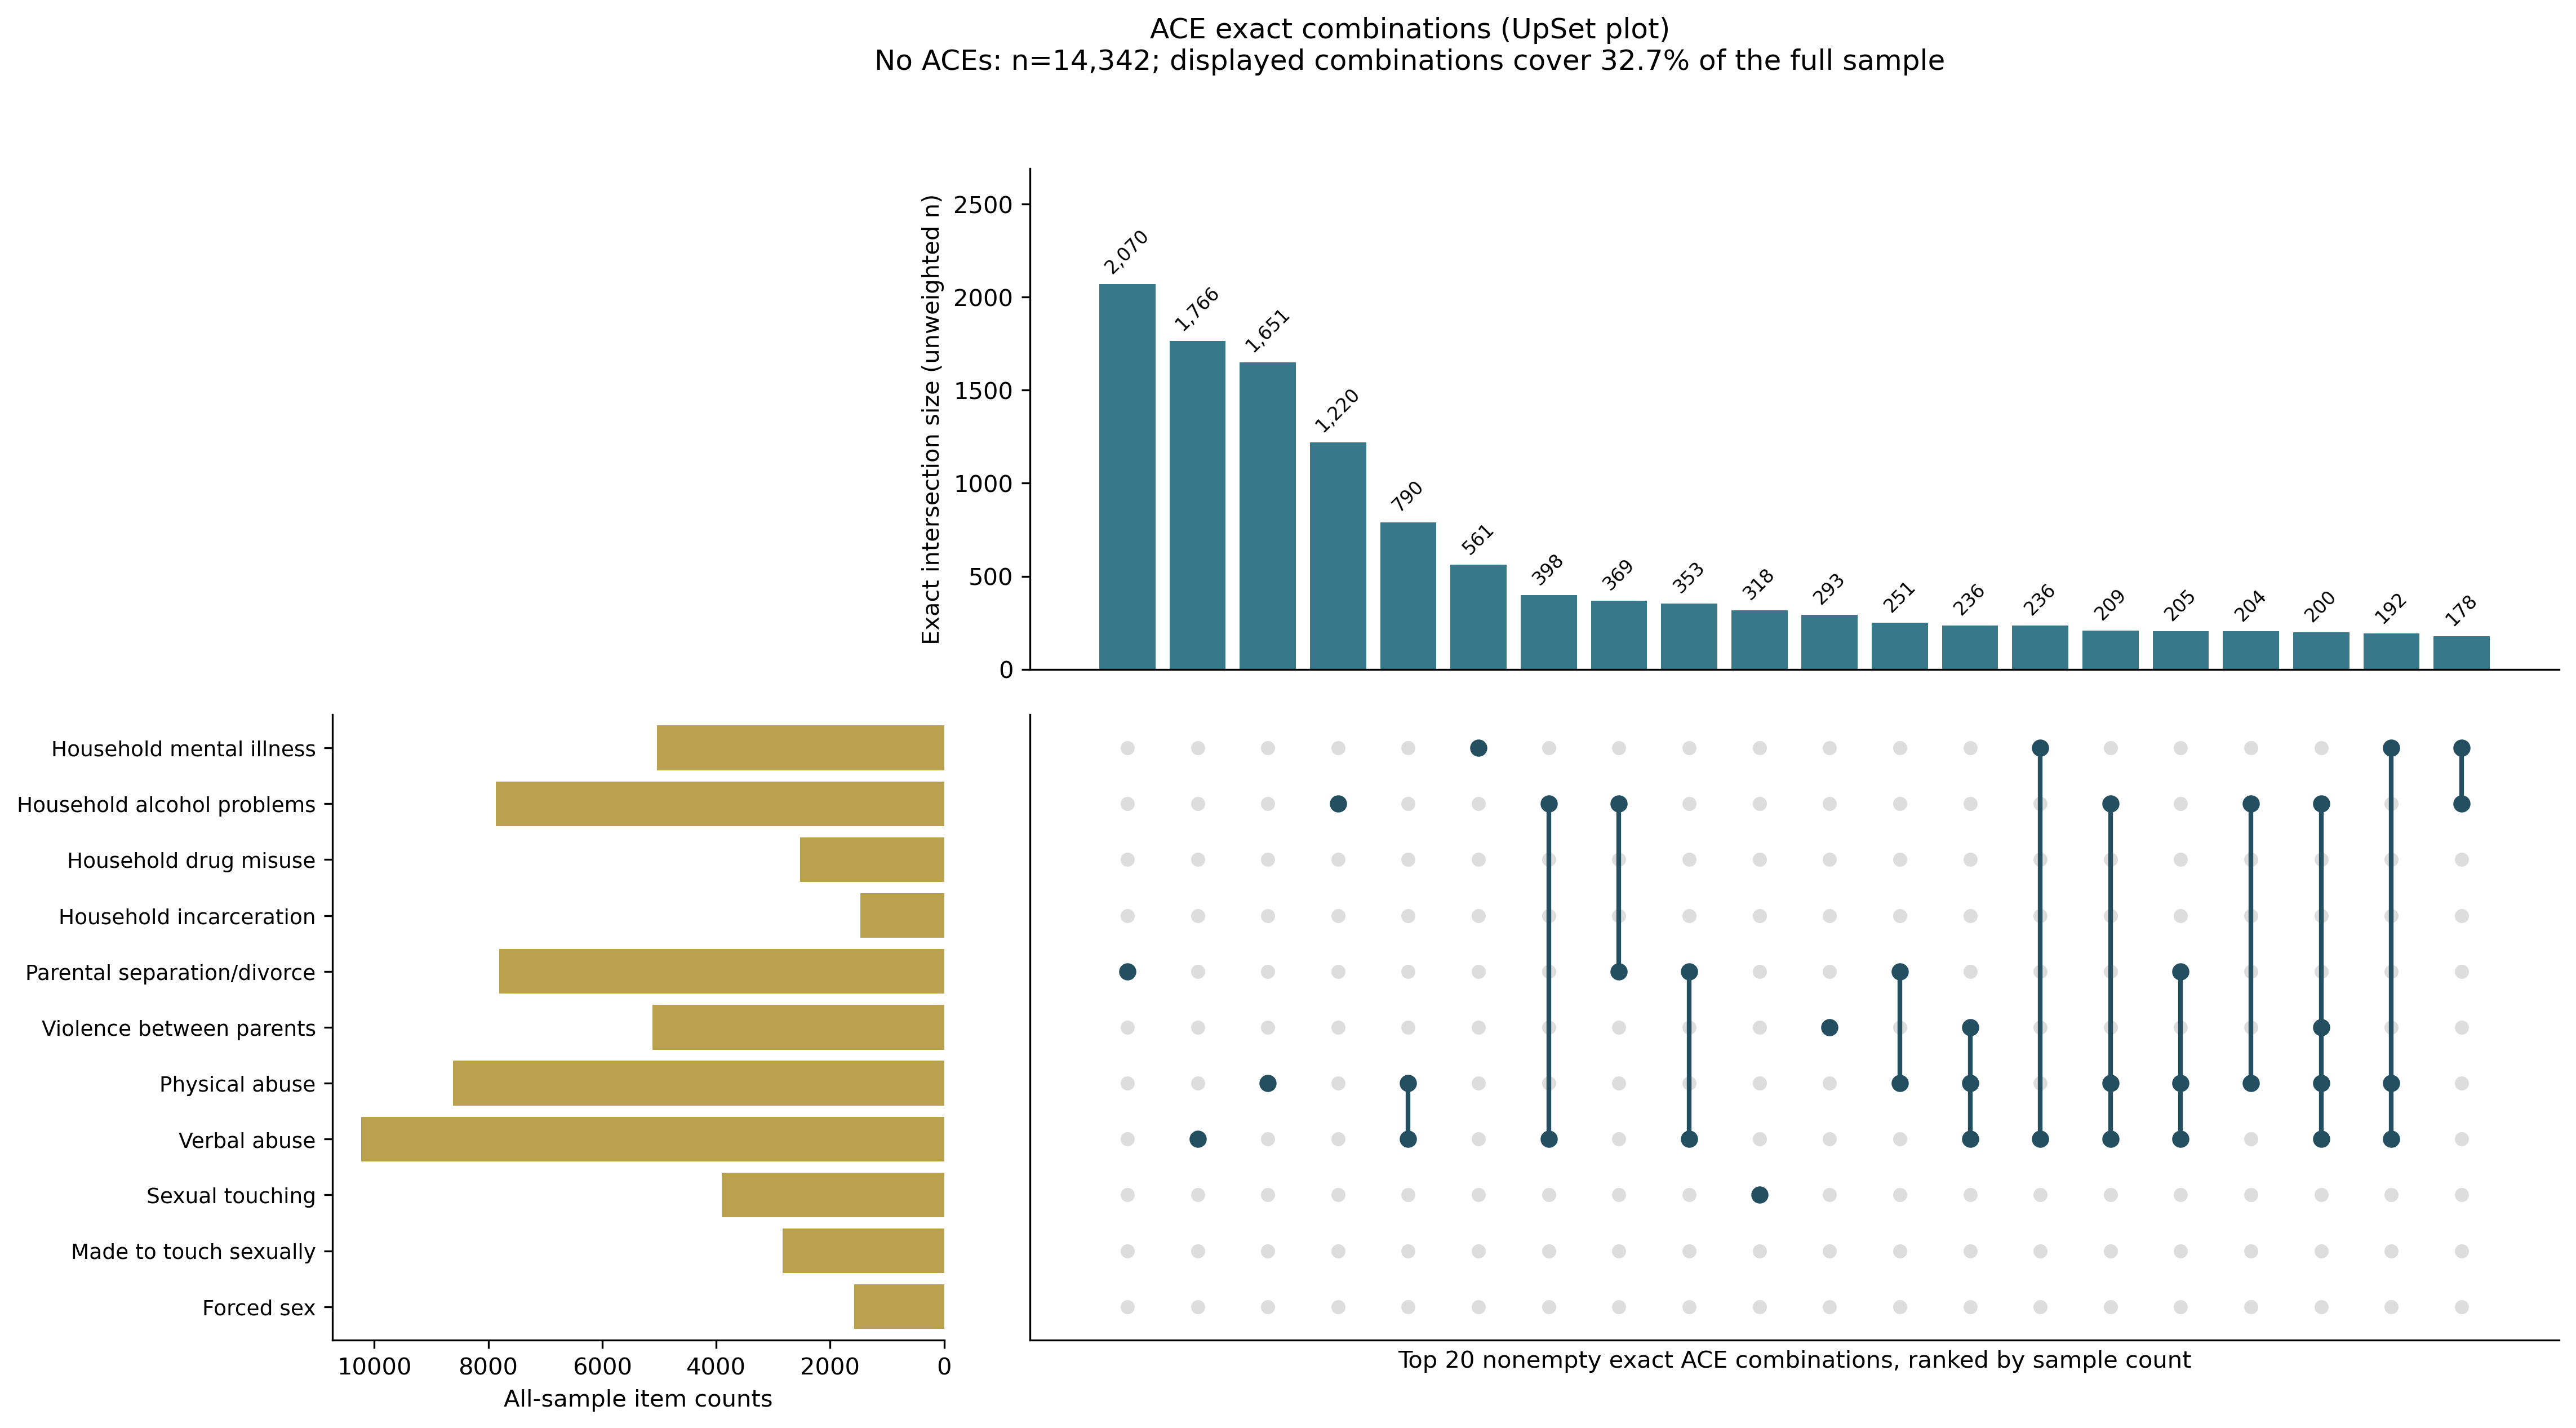

,pattern,description,n,unweighted_pct,weighted_pct
0,00000000000,No ACEs,14342,40.113,38.775
1,00001000000,Parental separation/divorce,2070,5.790,6.806
2,00000001000,Verbal abuse,1766,4.939,4.939
3,00000010000,Physical abuse,1651,4.618,4.778
4,01000000000,Household alcohol problems,1220,3.412,2.749
5,00000011000,Physical abuse + Verbal abuse,790,2.210,2.225
6,10000000000,Household mental illness,561,1.569,1.474
7,01000001000,Household alcohol problems + Verbal abuse,398,1.113,1.123
8,01001000000,Household alcohol problems + Parental separati...,369,1.032,1.190
9,00001001000,Parental separation/divorce + Verbal abuse,353,0.987,1.127


In [7]:
display(Image(filename=str(ROOT / 'figures/Fig3_ACE_UpSet_top20.png')))
display(result['patterns'][['pattern', 'description', 'n', 'unweighted_pct', 'weighted_pct']].head(21).round(3))

## 5. Demographic composition across ACE score groups

Compare sex, education, household income, age, marital status, and race/ethnicity within each ACE group. Each 100% stacked bar uses its own group as the denominator and retains Missing as a separate category. Recoding follows the existing descriptive analysis. These comparisons are descriptive; no significance testing or causal inference is performed.

,variable,level,0,1,2-3,4+
0,age_group,45-54,"1,887 (20.0%)","1,371 (23.1%)","1,527 (27.1%)","1,626 (36.0%)"
1,age_group,55-64,"3,052 (25.9%)","1,989 (28.7%)","2,089 (31.2%)","1,829 (34.9%)"
2,age_group,65-74,"4,604 (28.4%)","2,631 (29.2%)","2,380 (25.4%)","1,427 (20.9%)"
3,age_group,75+,"4,799 (25.7%)","2,254 (19.0%)","1,653 (16.3%)",636 (8.2%)
4,age_group,Missing,0 (0.0%),0 (0.0%),0 (0.0%),0 (0.0%)
5,education,Attended college,"3,538 (29.7%)","2,095 (30.5%)","1,972 (30.7%)","1,707 (34.7%)"
6,education,College graduate,"6,780 (36.9%)","3,732 (34.9%)","3,478 (34.1%)","2,108 (25.9%)"
7,education,High school or less,"3,976 (33.0%)","2,399 (34.4%)","2,183 (35.1%)","1,690 (39.1%)"
8,education,Missing,48 (0.4%),19 (0.2%),16 (0.2%),13 (0.2%)
9,income,$100-200k,"2,477 (18.3%)","1,509 (19.3%)","1,474 (19.7%)",996 (19.4%)


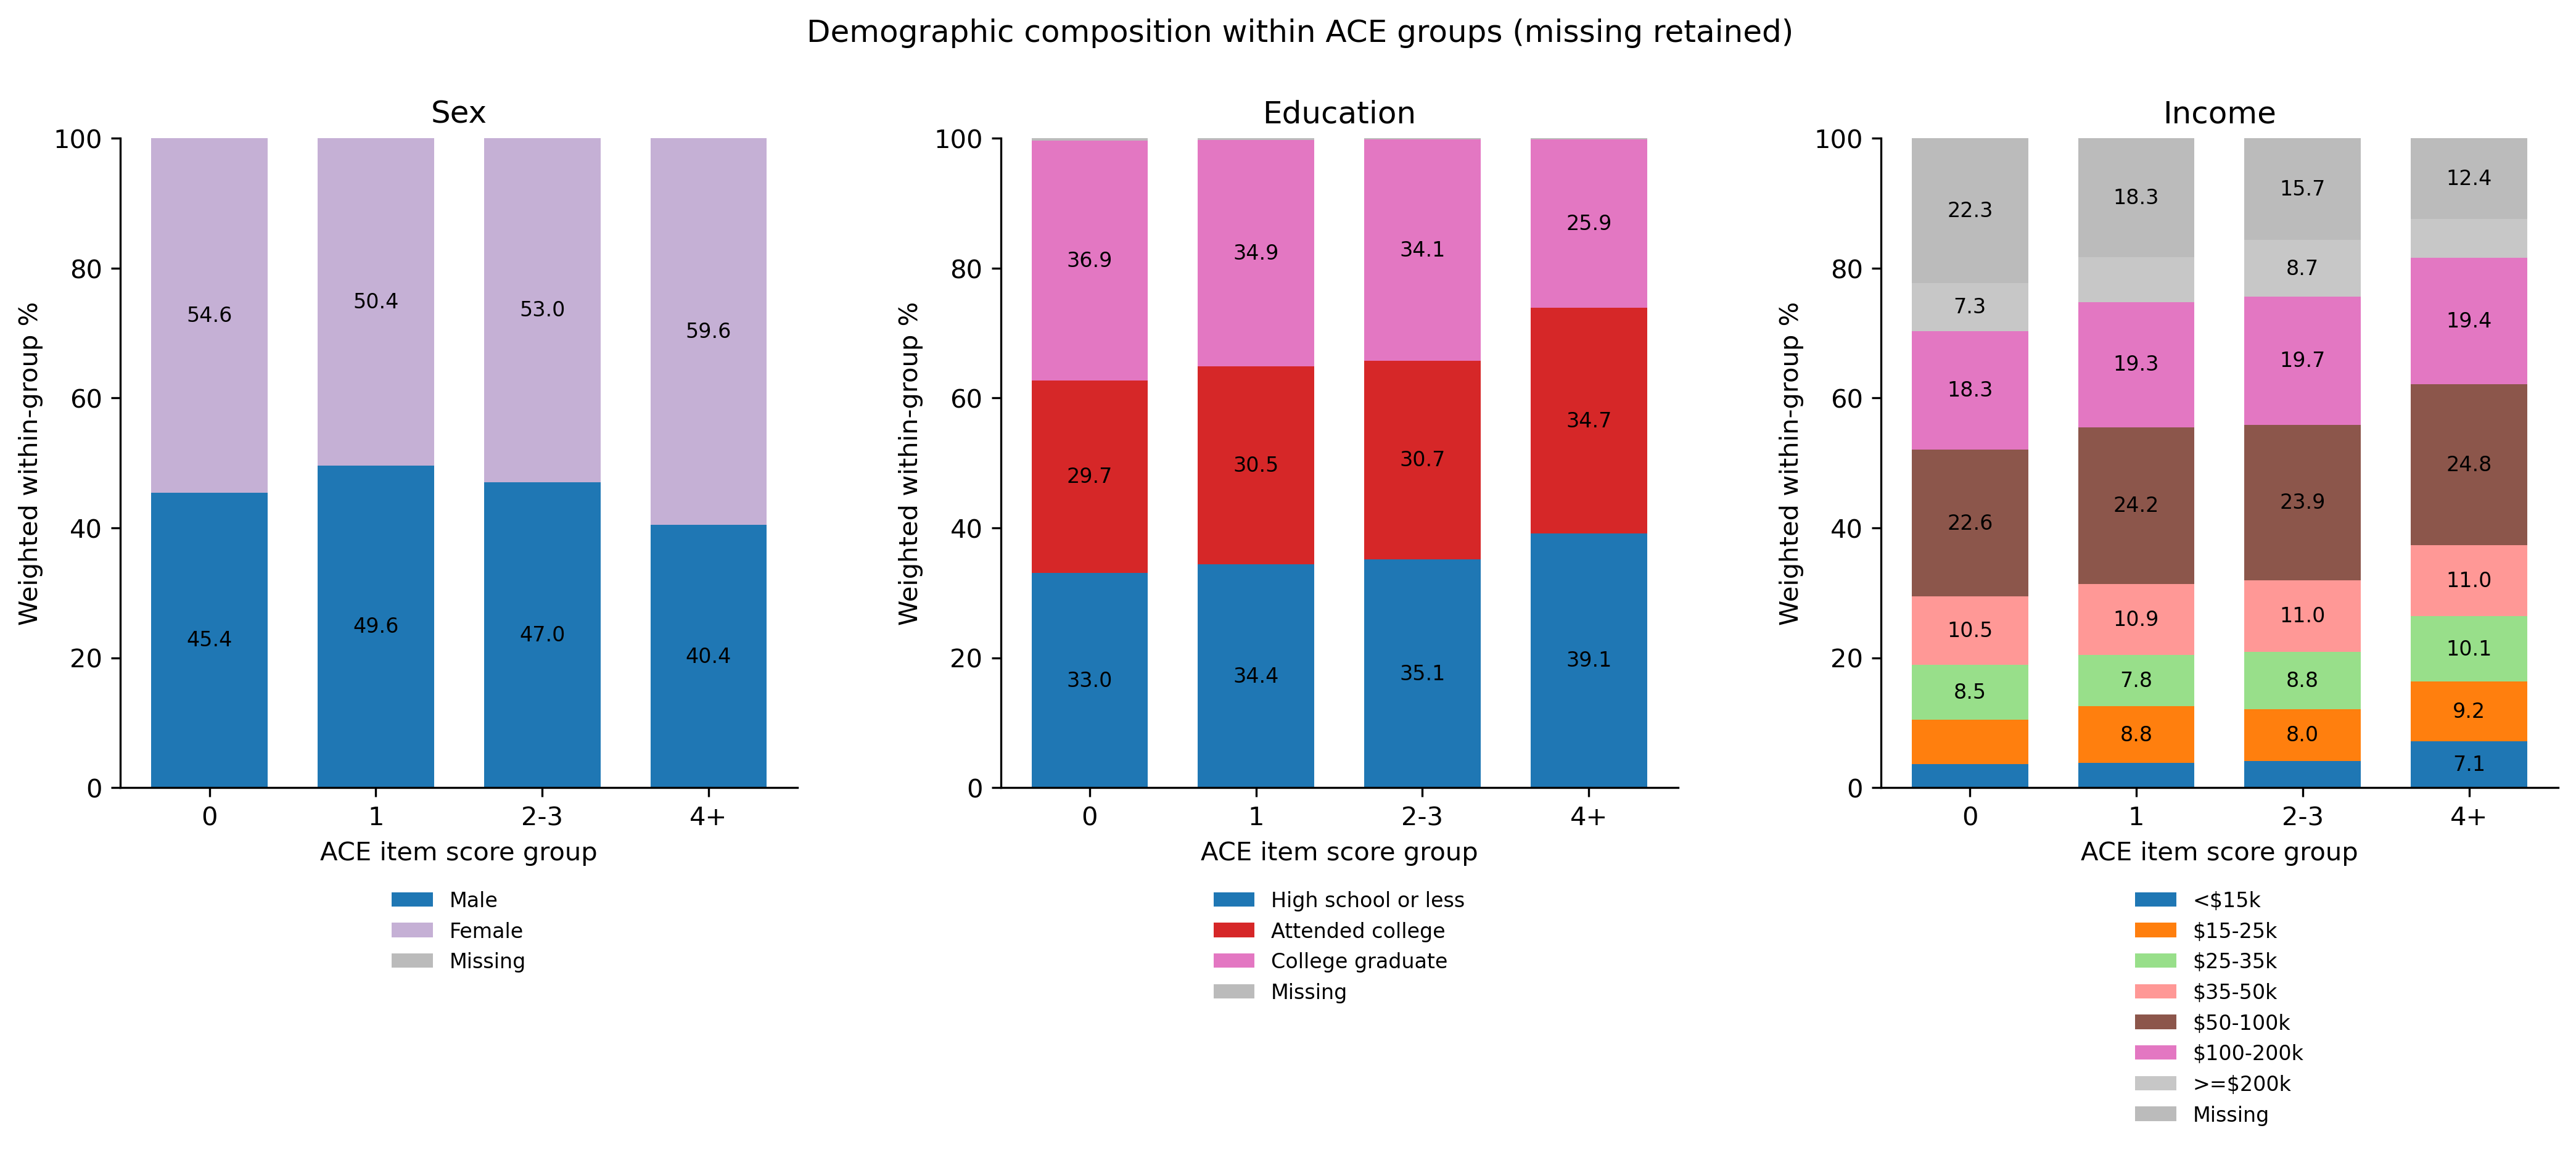

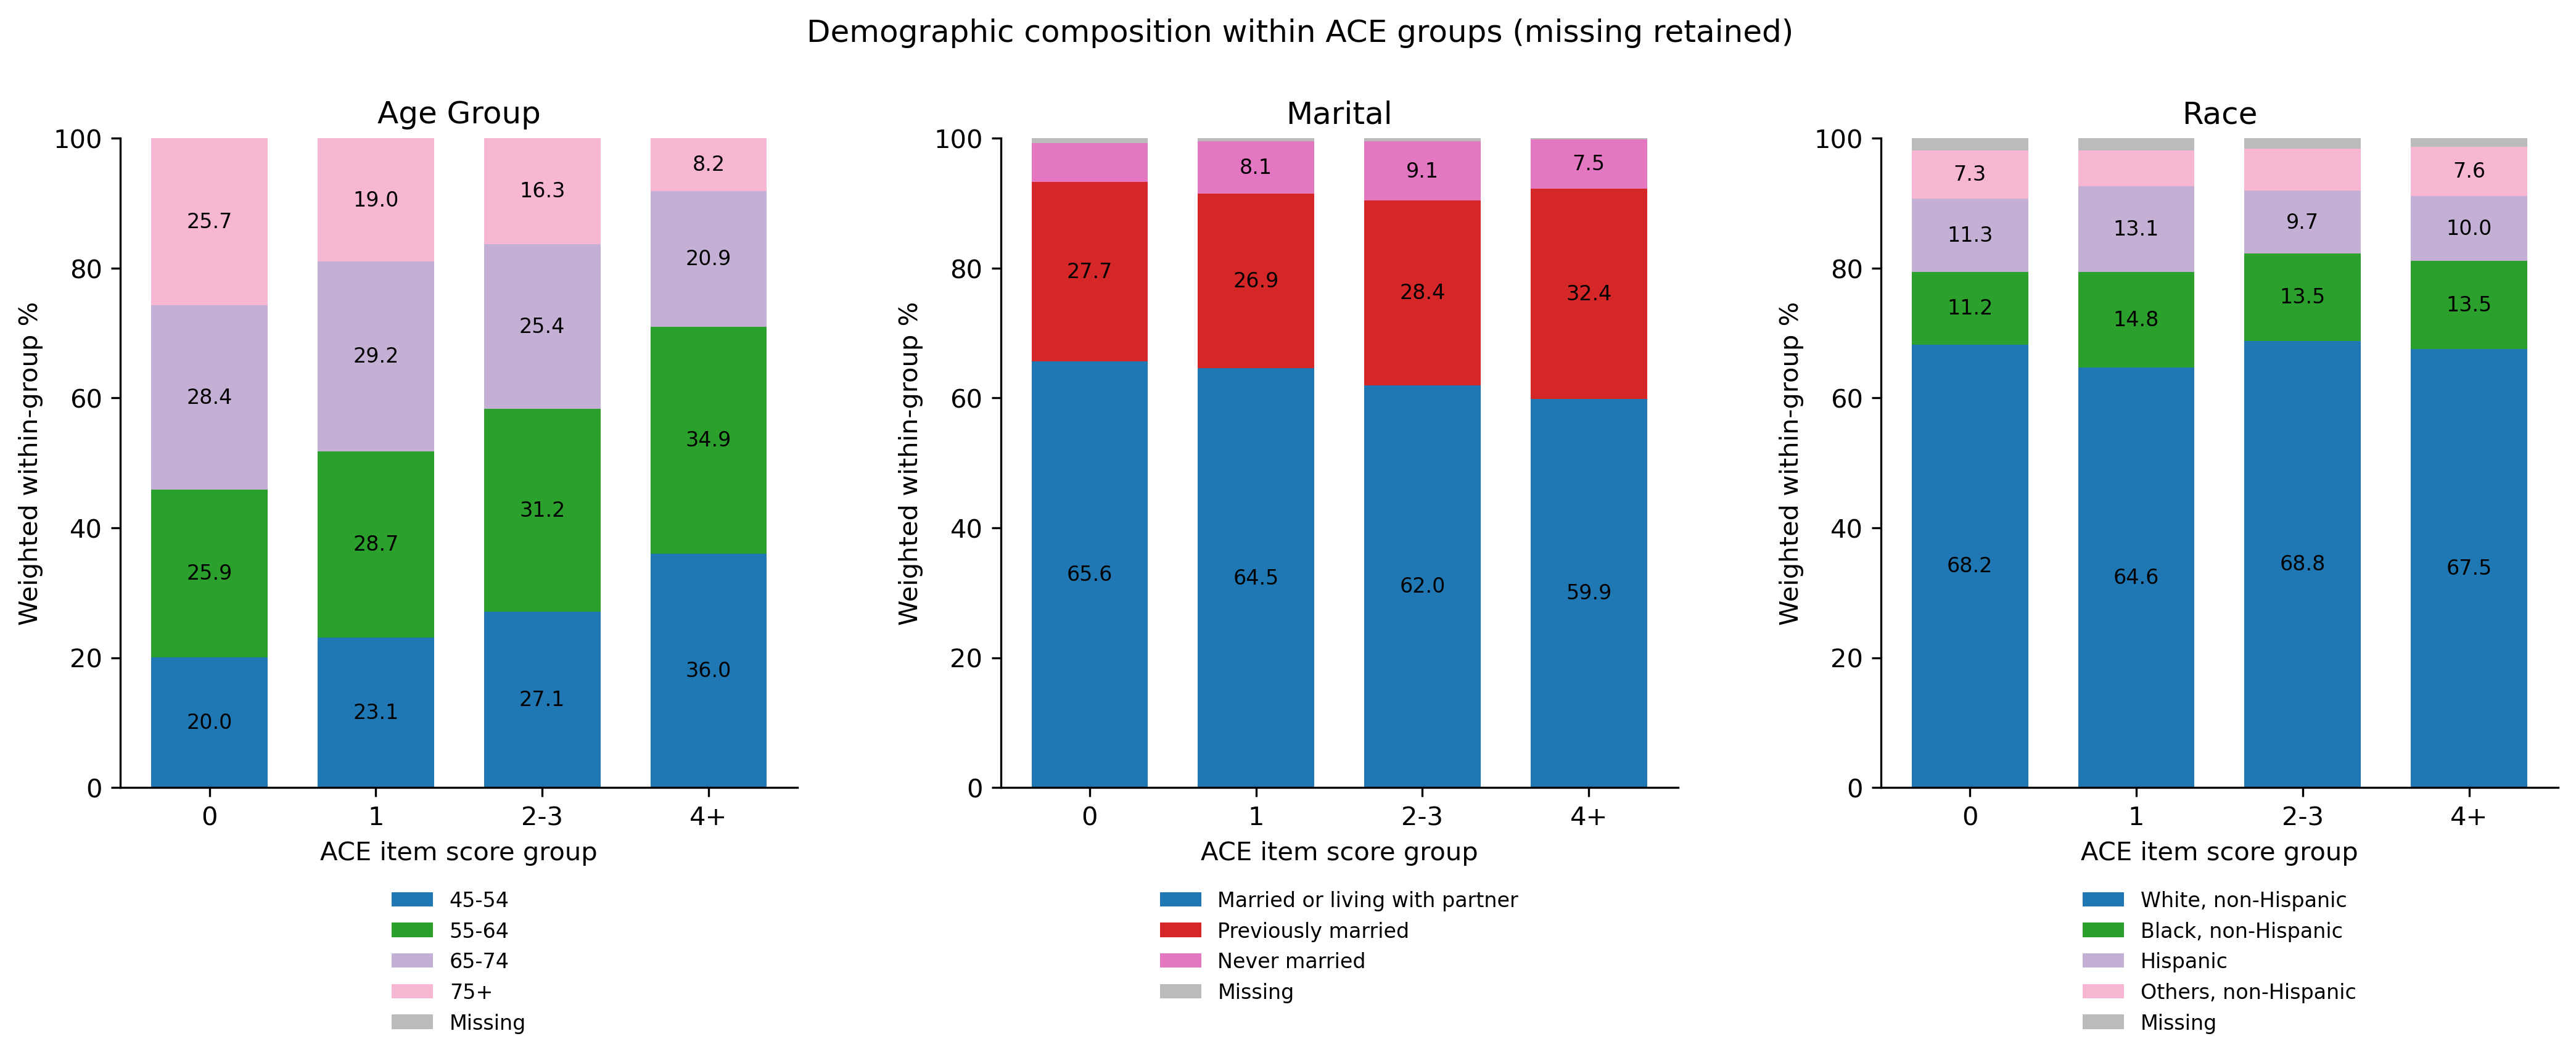

In [8]:
demo = result['demographics']
display(pd.read_csv(ROOT / 'tables/demographics_by_ace_group_n_weighted_pct.csv').fillna(''))
display(Image(filename=str(ROOT / 'figures/Fig4_demographics_sex_education_income.png')))
display(Image(filename=str(ROOT / 'figures/Fig5_demographics_age_group_marital_race.png')))

## 6. LCA analysis

See [ACE_LCA_EN.ipynb](ACE_LCA_EN.ipynb) for model fitting and diagnostics. English-language results are saved under `english/lca/`. The descriptive analysis and LCA notebooks can be reproduced independently.